# 08 — Penetapan Kohort Final dan Pembagian Fold

> [!IMPORTANT]
> **Konteks Alur Penelitian: Kohort Awal ABIDE I (PCP)**
> Notebook ini adalah bagian dari alur studi pendahuluan khusus **ABIDE I (PCP/C-PAC & FreeSurfer 5.1)** dengan kohort awal N = 987.
> Untuk penelitian gabungan multi-situs utama (**ABIDE I + ABIDE II**) yang menggunakan pipeline seragam **DCAN (ABCD-HCP)** dengan total kohort final **N = 1.638 subjek**, silakan merujuk langsung ke **Notebook 09 (09_kohort_dcan_abide1_abide2.ipynb)**. Kohort 987 subjek ABIDE I ini menjadi salah satu saringan awal sebelum digabungkan dengan ABIDE II dan melalui QC gerak ketat FD < 0,3 mm di Notebook 09.


Notebook ini menggabungkan semua kriteria inklusi menjadi **satu daftar subjek resmi** (`data/processed/kohort_final.csv`) yang dipakai oleh **semua skenario**, sehingga perbandingan antar skenario adil (subjek sama, fold sama).

> **Peran dalam alur akhir penelitian.** Notebook 06 → 07 → 08 menentukan **987 subjek ABIDE I** (`kohort_final.csv`). Daftar ini lalu dipakai notebook 09 sebagai saringan subjek ABIDE I pada kohort gabungan ABIDE I + II (1.638 subjek), yang dipakai skenario S1–S4. Data yang dipakai skenario sendiri berasal dari **turunan DCAN**, bukan PCP.

### Kriteria inklusi (ditetapkan sebelum melihat hasil model)

| No | Kriteria | Alasan |
| :---: | :--- | :--- |
| 1 | Memiliki fMRI & sMRI mentah di ABIDE I | Dasar penelitian multimodal (notebook 06) |
| 2 | `FILE_ID` ≠ `no_filename` | Subjek tanpa `FILE_ID` tidak termasuk rilis resmi PCP |
| 3 | Time series `filt_global` tersedia untuk **4 atlas** | Dibutuhkan skenario multi-atlas |
| 4 | ROI datar **≤ 5%** pada setiap atlas | ROI datar tidak memiliki informasi konektivitas |
| 5 | Statistik FreeSurfer PCP tersedia | Dibutuhkan cabang sMRI |
| 6 | **Lolos QC FreeSurfer** (notebook 07) | Membuang kegagalan segmentasi |

### Pembagian fold
* **5-fold** bertingkat (*stratified*) berdasarkan kombinasi **situs × diagnosis**, `random_state = 42`, sehingga proporsi ASD/kontrol dan situs seimbang di setiap fold.
* Evaluasi **leave-one-site-out (LOSO)** memakai kolom `SITE_ID`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from IPython.display import display
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent

PROC = ROOT / "data" / "processed"
FIG_DIR = ROOT / "result" / "figure"
TABEL_DIR = ROOT / "result" / "tabel"
KOHORT_CSV = PROC / "kohort_final.csv"

BATAS_ROI_DATAR = 0.05
N_FOLD, SEED = 5, 42
ATLAS = {"aal": 116, "harvard_oxford": 111, "cc200": 200, "cc400": 392}

pheno_mentah = pd.read_csv(ROOT / "data" / "phenotypic" / "Phenotypic_V1_0b.csv")
pheno = pd.read_csv(ROOT / "data" / "phenotypic" / "phenotypic_clean.csv")
unduh = pd.read_csv(PROC / "download_summary_pcp_filt_global.csv")
unduh_noglobal = pd.read_csv(PROC / "download_summary_pcp_filt_noglobal.csv")
smri = pd.read_csv(PROC / "smri_features" / "smri_freesurfer_fitur.csv", usecols=["SUB_ID", "FILE_ID"])
qc_fs = pd.read_csv(TABEL_DIR / "07b_qc_freesurfer.csv")

display(pd.DataFrame({
    "Sumber": ["Fenotipe ABIDE I asli", "Fenotipe bersih (notebook 03)", "Ringkasan unduhan filt_global",
               "Ringkasan unduhan filt_noglobal", "Fitur sMRI FreeSurfer (notebook 07b)", "QC FreeSurfer (notebook 07b)"],
    "Baris": [len(pheno_mentah), len(pheno), len(unduh), len(unduh_noglobal), len(smri), len(qc_fs)],
}))

,Sumber,Baris
0,Fenotipe ABIDE I asli,1112
1,Fenotipe bersih (notebook 03),1097
2,Ringkasan unduhan filt_global,4140
3,Ringkasan unduhan filt_noglobal,4140
4,Fitur sMRI FreeSurfer (notebook 07b),1035
5,QC FreeSurfer (notebook 07b),1035


## 1. Menerapkan Kriteria Satu per Satu

Informasi ROI datar dan panjang time series diambil dari ringkasan skrip unduh (`download_summary_pcp_filt_global.csv`), yang menghitungnya langsung dari setiap berkas time series.

,Tahap,Subjek tersisa,Dikeluarkan,ASD,Kontrol
0,0. Fenotipe ABIDE I asli,1112,-,539,573
1,1. fMRI & sMRI mentah tersedia (notebook 03),1097,15,531,566
2,2. FILE_ID ≠ no_filename,1035,62,505,530
3,3. Time series filt_global 4 atlas,1035,0,505,530
4,4. ROI datar ≤ 5% di setiap atlas,1009,26,489,520
5,5. Statistik FreeSurfer tersedia,1009,0,489,520
6,6. Lolos QC FreeSurfer,987,22,476,511


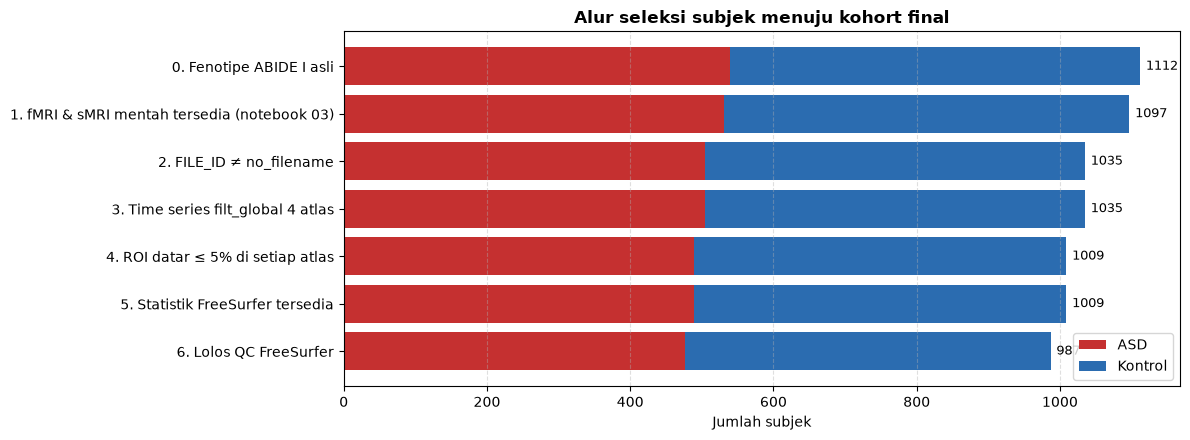

In [2]:
df = pheno.copy()

ok = unduh[unduh["status"] == "sukses"].copy()
ok["pct_datar"] = ok["n_roi_datar"] / ok["atlas"].map(ATLAS)
per_atlas = ok.pivot(index="file_id", columns="atlas", values="pct_datar")
per_atlas.columns = [f"pct_roi_datar_{c}" for c in per_atlas.columns]
n_waktu = ok.groupby("file_id")["n_waktu"].first()
df = df.merge(per_atlas, left_on="FILE_ID", right_index=True, how="left")
df["n_waktu"] = df["FILE_ID"].map(n_waktu)

fs = (smri.rename(columns={"FILE_ID": "freesurfer_folder"})
      .merge(qc_fs[["SUB_ID", "gagal_qc"]], on="SUB_ID", how="left"))
df = df.merge(fs, on="SUB_ID", how="left")

kolom_datar = [f"pct_roi_datar_{a}" for a in ATLAS]
df["k2_ada_file_id"] = df["FILE_ID"] != "no_filename"
df["k3_fmri_4_atlas"] = df[kolom_datar].notna().all(axis=1)
df["k4_roi_datar_ok"] = (df[kolom_datar] <= BATAS_ROI_DATAR).all(axis=1)
df["k5_ada_freesurfer"] = df["freesurfer_folder"].notna()
df["k6_lolos_qc_fs"] = df["gagal_qc"].eq(False)

kriteria = [("1. fMRI & sMRI mentah tersedia (notebook 03)", None),
            ("2. FILE_ID ≠ no_filename", "k2_ada_file_id"),
            ("3. Time series filt_global 4 atlas", "k3_fmri_4_atlas"),
            ("4. ROI datar ≤ 5% di setiap atlas", "k4_roi_datar_ok"),
            ("5. Statistik FreeSurfer tersedia", "k5_ada_freesurfer"),
            ("6. Lolos QC FreeSurfer", "k6_lolos_qc_fs")]

masuk = pd.Series(True, index=df.index)
alur = [{"Tahap": "0. Fenotipe ABIDE I asli", "Subjek tersisa": len(pheno_mentah), "Dikeluarkan": "-",
         "ASD": int((pheno_mentah["DX_GROUP"] == 1).sum()), "Kontrol": int((pheno_mentah["DX_GROUP"] == 2).sum())}]
for nama, kol in kriteria:
    sebelum = masuk.sum()
    if kol is not None:
        masuk &= df[kol]
    alur.append({"Tahap": nama, "Subjek tersisa": int(masuk.sum()),
                 "Dikeluarkan": len(pheno_mentah) - len(df) if kol is None else int(sebelum - masuk.sum()),
                 "ASD": int((masuk & (df["DX_GROUP"] == 1)).sum()), "Kontrol": int((masuk & (df["DX_GROUP"] == 2)).sum())})
df_alur = pd.DataFrame(alur)
df_alur.to_csv(TABEL_DIR / "08_alur_eksklusi.csv", index=False)
display(df_alur)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.barh(df_alur["Tahap"][::-1], df_alur["ASD"][::-1], color="#C53030", label="ASD")
ax.barh(df_alur["Tahap"][::-1], df_alur["Kontrol"][::-1], left=df_alur["ASD"][::-1], color="#2B6CB0", label="Kontrol")
for y, (n, t) in enumerate(zip(df_alur["Subjek tersisa"][::-1], df_alur["Tahap"][::-1])):
    ax.text(n + 8, y, str(n), va="center", fontsize=9)
ax.set_xlabel("Jumlah subjek"); ax.set_title("Alur seleksi subjek menuju kohort final", fontweight="bold")
ax.legend(loc="lower right"); ax.grid(axis="x", alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "08_1_alur_seleksi_kohort.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.1 Rincian Alasan Eksklusi pada Kriteria ROI Datar

Atlas mana yang paling sering menyebabkan subjek dikeluarkan karena ROI datar > 5%?

In [3]:
tahap4 = df[df["k2_ada_file_id"] & df["k3_fmri_4_atlas"]]
display(pd.DataFrame({
    "Atlas": list(ATLAS),
    "Subjek dengan ROI datar > 5%": [int((tahap4[f"pct_roi_datar_{a}"] > BATAS_ROI_DATAR).sum()) for a in ATLAS],
    "Maks. % ROI datar": [f"{tahap4[f'pct_roi_datar_{a}'].max() * 100:.1f}%" for a in ATLAS],
}))
keluar_datar = tahap4[~tahap4["k4_roi_datar_ok"]]
display(keluar_datar.groupby("SITE_ID").size().sort_values(ascending=False).to_frame("Subjek dikeluarkan")
        .style.set_caption("Subjek dikeluarkan karena ROI datar, per situs"))

,Atlas,Subjek dengan ROI datar > 5%,Maks. % ROI datar
0,aal,24,56.0%
1,harvard_oxford,8,52.3%
2,cc200,9,59.0%
3,cc400,16,60.5%


,Subjek dikeluarkan
SITE_ID,
CMU,9
CALTECH,8
SDSU,4
SBL,3
PITT,1
LEUVEN_2,1


## 2. Kohort Final: Distribusi per Situs

LABEL,ASD,Kontrol,Total,% ASD
SITE_ID,,,,
NYU,71,99,170,41.8
UM_1,46,51,97,47.4
UCLA_1,41,31,72,56.9
USM,46,25,71,64.8
PITT,29,26,55,52.7
YALE,28,26,54,51.9
MAX_MUN,24,28,52,46.2
KKI,20,27,47,42.6
TRINITY,22,25,47,46.8


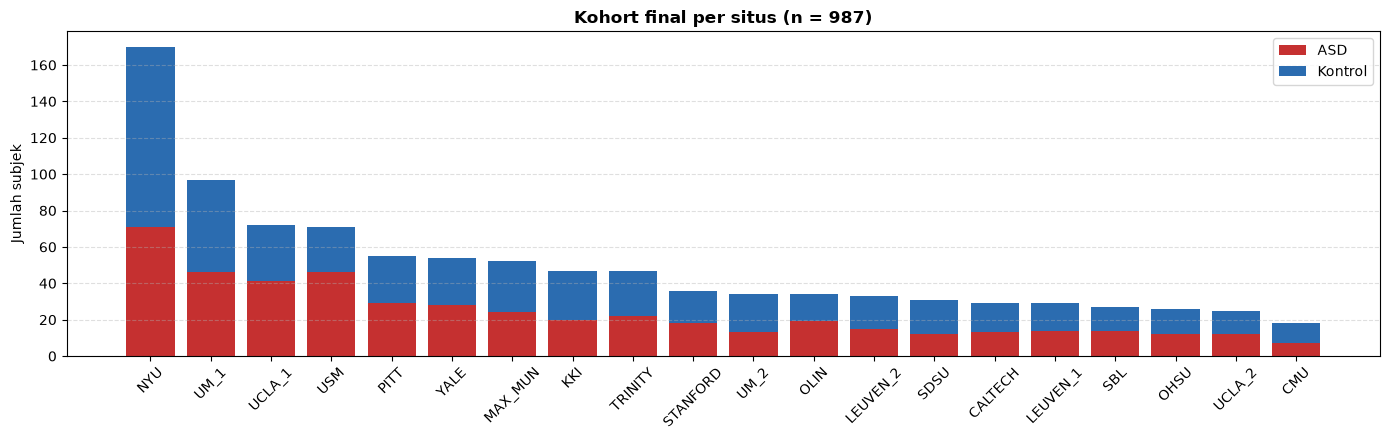

In [4]:
kohort = df[masuk].copy()
kohort["LABEL_BIN"] = (kohort["DX_GROUP"] == 1).astype(int)

per_situs = (kohort.groupby("SITE_ID")["LABEL"].value_counts().unstack(fill_value=0)
             .reindex(columns=["ASD", "Kontrol"]))
per_situs["Total"] = per_situs.sum(axis=1)
per_situs["% ASD"] = (per_situs["ASD"] / per_situs["Total"] * 100).round(1)
per_situs = per_situs.sort_values("Total", ascending=False)
display(per_situs)
per_situs.to_csv(TABEL_DIR / "08_kohort_per_situs.csv")

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(per_situs.index, per_situs["ASD"], color="#C53030", label="ASD")
ax.bar(per_situs.index, per_situs["Kontrol"], bottom=per_situs["ASD"], color="#2B6CB0", label="Kontrol")
ax.set_ylabel("Jumlah subjek"); ax.set_title(f"Kohort final per situs (n = {len(kohort)})", fontweight="bold")
ax.tick_params(axis="x", rotation=45); ax.legend(); ax.grid(axis="y", alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "08_2_kohort_per_situs.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Karakteristik Demografis ASD vs Kontrol

Uji statistik: *Welch t-test* untuk variabel kontinu, *chi-square* untuk jenis kelamin. IQ memakai **nilai asli sebelum imputasi** (`FIQ_RAW`), sehingga subjek tanpa nilai IQ tidak ikut dihitung.

,Variabel,ASD,Kontrol,p-value
0,Jumlah subjek,476,511,-
1,Umur (tahun),16.9 ± 8.4 (n=476),16.8 ± 7.4 (n=511),0.837
2,Full-scale IQ,105.4 ± 16.9 (n=445),110.9 ± 12.4 (n=477),2.7e-08
3,Verbal IQ,104.0 ± 18.1 (n=397),111.4 ± 13.4 (n=414),7.43e-11
4,Performance IQ,105.1 ± 17.1 (n=399),107.6 ± 13.1 (n=426),0.0187
5,Panjang time series (frame),192.4 ± 56.8 (n=476),193.7 ± 58.6 (n=511),0.729
6,Laki-laki / perempuan,420 / 56,417 / 94,0.00494


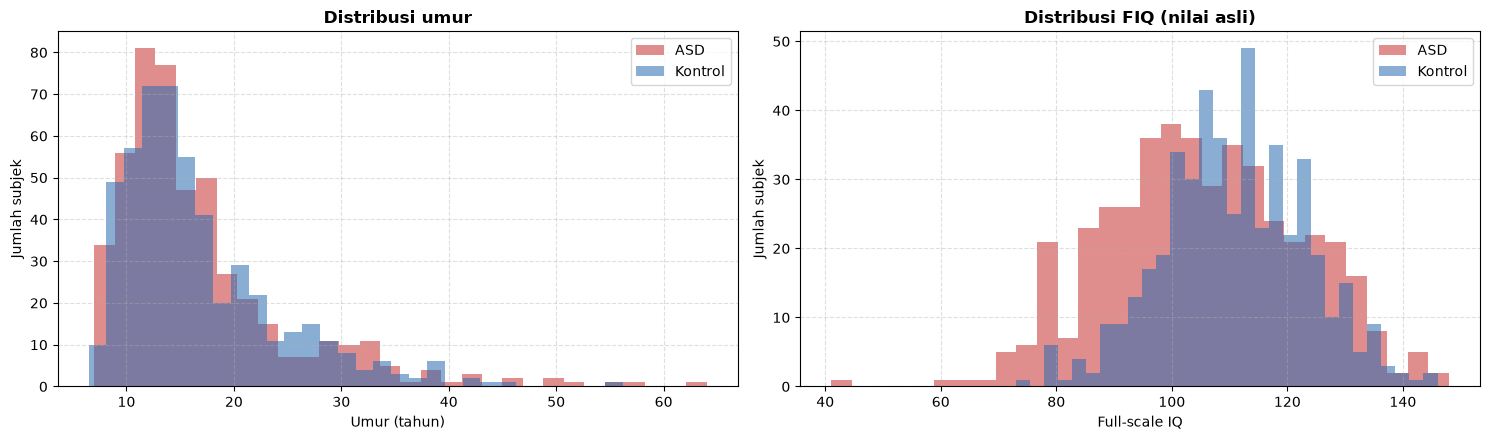

In [5]:
def ringkas(x):
    return f"{x.mean():.1f} ± {x.std():.1f} (n={x.notna().sum()})"

asd, tc = kohort[kohort["DX_GROUP"] == 1], kohort[kohort["DX_GROUP"] == 2]
baris = []
for kol, nama in [("AGE_AT_SCAN", "Umur (tahun)"), ("FIQ_RAW", "Full-scale IQ"), ("VIQ_RAW", "Verbal IQ"),
                  ("PIQ_RAW", "Performance IQ"), ("n_waktu", "Panjang time series (frame)")]:
    p = stats.ttest_ind(asd[kol].dropna(), tc[kol].dropna(), equal_var=False).pvalue
    baris.append({"Variabel": nama, "ASD": ringkas(asd[kol]), "Kontrol": ringkas(tc[kol]), "p-value": f"{p:.3g}"})
tabel_sex = pd.crosstab(kohort["DX_GROUP"], kohort["SEX"])
p_sex = stats.chi2_contingency(tabel_sex)[1]
baris.append({"Variabel": "Laki-laki / perempuan",
              "ASD": f"{(asd['SEX'] == 1).sum()} / {(asd['SEX'] == 2).sum()}",
              "Kontrol": f"{(tc['SEX'] == 1).sum()} / {(tc['SEX'] == 2).sum()}", "p-value": f"{p_sex:.3g}"})
baris.insert(0, {"Variabel": "Jumlah subjek", "ASD": len(asd), "Kontrol": len(tc), "p-value": "-"})
df_demo = pd.DataFrame(baris)
df_demo.to_csv(TABEL_DIR / "08_demografi_kohort.csv", index=False)
display(df_demo)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for d, warna, nama in [(asd, "#C53030", "ASD"), (tc, "#2B6CB0", "Kontrol")]:
    axes[0].hist(d["AGE_AT_SCAN"], bins=30, alpha=0.55, color=warna, label=nama)
    axes[1].hist(d["FIQ_RAW"].dropna(), bins=30, alpha=0.55, color=warna, label=nama)
axes[0].set_xlabel("Umur (tahun)"); axes[0].set_title("Distribusi umur", fontweight="bold")
axes[1].set_xlabel("Full-scale IQ"); axes[1].set_title("Distribusi FIQ (nilai asli)", fontweight="bold")
for a in axes:
    a.set_ylabel("Jumlah subjek"); a.legend(); a.grid(alpha=0.4, ls="--")
plt.tight_layout()
fig.savefig(FIG_DIR / "08_3_demografi_kohort.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Pemeriksaan Bias Seleksi

Apakah subjek yang dikeluarkan berbeda secara sistematis dari subjek yang dipertahankan? Jika proporsi ASD atau umur sangat berbeda, proses seleksi bisa membiaskan hasil.

In [6]:
keluar = df[~masuk]
p_dx = stats.chi2_contingency(pd.crosstab(masuk, df["DX_GROUP"]))[1]
p_umur = stats.ttest_ind(df.loc[masuk, "AGE_AT_SCAN"], keluar["AGE_AT_SCAN"], equal_var=False).pvalue
display(pd.DataFrame({
    "Ukuran": ["Jumlah subjek", "% ASD", "Umur rata-rata", "p-value proporsi ASD (chi-square)", "p-value umur (t-test)"],
    "Dipertahankan": [int(masuk.sum()), f"{(df.loc[masuk, 'DX_GROUP'] == 1).mean() * 100:.1f}%",
                      f"{df.loc[masuk, 'AGE_AT_SCAN'].mean():.1f}", f"{p_dx:.3g}", f"{p_umur:.3g}"],
    "Dikeluarkan": [len(keluar), f"{(keluar['DX_GROUP'] == 1).mean() * 100:.1f}%",
                    f"{keluar['AGE_AT_SCAN'].mean():.1f}", "", ""],
}))

,Ukuran,Dipertahankan,Dikeluarkan
0,Jumlah subjek,987,110
1,% ASD,48.2%,50.0%
2,Umur rata-rata,16.8,18.7
3,p-value proporsi ASD (chi-square),0.801,
4,p-value umur (t-test),0.026,


## 5. Pembagian Fold

Fold dibentuk dengan `StratifiedKFold` pada kunci gabungan **situs × diagnosis**, sehingga setiap fold memuat proporsi ASD/kontrol dan komposisi situs yang mirip. Kolom `fold` disimpan di berkas kohort dan **wajib dipakai oleh semua skenario**.

In [7]:
kunci = kohort["SITE_ID"] + "_" + kohort["DX_GROUP"].astype(str)
print(f"Strata terkecil (situs × diagnosis): {kunci.value_counts().min()} subjek "
      f"→ {'cukup' if kunci.value_counts().min() >= N_FOLD else 'KURANG'} untuk {N_FOLD} fold")

skf = StratifiedKFold(n_splits=N_FOLD, shuffle=True, random_state=SEED)
kohort["fold"] = -1
for k, (_, idx_uji) in enumerate(skf.split(kohort, kunci)):
    kohort.iloc[idx_uji, kohort.columns.get_loc("fold")] = k

cek_fold = kohort.groupby("fold").agg(subjek=("SUB_ID", "count"), pct_asd=("LABEL_BIN", "mean"),
                                       jumlah_situs=("SITE_ID", "nunique"), umur_rata2=("AGE_AT_SCAN", "mean"))
cek_fold["pct_asd"] = (cek_fold["pct_asd"] * 100).round(1)
display(cek_fold.round(1))

Strata terkecil (situs × diagnosis): 7 subjek → cukup untuk 5 fold


,subjek,pct_asd,jumlah_situs,umur_rata2
fold,,,,
0,198,47.5,20,17.0
1,198,49.5,20,17.2
2,197,48.2,20,16.4
3,197,47.2,20,16.3
4,197,48.7,20,17.3


## 6. Menyimpan Kohort Final

In [8]:
kolom_simpan = ["SUB_ID", "FILE_ID", "SITE_ID", "DX_GROUP", "LABEL_BIN", "AGE_AT_SCAN", "SEX",
                "FIQ", "VIQ", "PIQ", "FIQ_RAW", "VIQ_RAW", "PIQ_RAW", "HANDEDNESS_CATEGORY", "HANDEDNESS_RAW",
                "n_waktu", *kolom_datar, "freesurfer_folder", "fold"]
kohort_final = kohort[kolom_simpan].sort_values(["SITE_ID", "SUB_ID"]).reset_index(drop=True)
kohort_final.to_csv(KOHORT_CSV, index=False)

n_atlas_noglobal = unduh_noglobal[unduh_noglobal["status"] == "sukses"].groupby("file_id").size()
lengkap_noglobal = kohort_final["FILE_ID"].map(n_atlas_noglobal).eq(len(ATLAS))

display(pd.DataFrame({
    "Ukuran": ["Subjek kohort final", "ASD / kontrol", "Situs", "Jumlah fold",
               "Subjek dengan data filt_noglobal lengkap (untuk ablasi GSR)", "Berkas"],
    "Nilai": [len(kohort_final), f"{kohort_final['LABEL_BIN'].sum()} / {(kohort_final['LABEL_BIN'] == 0).sum()}",
              kohort_final["SITE_ID"].nunique(), N_FOLD, int(lengkap_noglobal.sum()), str(KOHORT_CSV.relative_to(ROOT))],
}))
display(kohort_final.head())

,Ukuran,Nilai
0,Subjek kohort final,987
1,ASD / kontrol,476 / 511
2,Situs,20
3,Jumlah fold,5
4,Subjek dengan data filt_noglobal lengkap (untu...,987
5,Berkas,data\processed\kohort_final.csv


,SUB_ID,FILE_ID,SITE_ID,DX_GROUP,LABEL_BIN,AGE_AT_SCAN,SEX,FIQ,VIQ,PIQ,...,PIQ_RAW,HANDEDNESS_CATEGORY,HANDEDNESS_RAW,n_waktu,pct_roi_datar_aal,pct_roi_datar_harvard_oxford,pct_roi_datar_cc200,pct_roi_datar_cc400,freesurfer_folder,fold
0,51456,Caltech_0051456,CALTECH,1,1,55.4,1,126.0,118.0,128.0,...,128.0,R,R,146.0,0.000000,0.009009,0.005,0.010204,Caltech_0051456,4
1,51457,Caltech_0051457,CALTECH,1,1,22.9,1,107.0,119.0,93.0,...,93.0,Ambi,Ambi,146.0,0.008621,0.045045,0.005,0.017857,Caltech_0051457,3
2,51458,Caltech_0051458,CALTECH,1,1,39.2,1,93.0,80.0,108.0,...,108.0,R,R,146.0,0.034483,0.018018,0.005,0.022959,Caltech_0051458,0
3,51459,Caltech_0051459,CALTECH,1,1,22.8,1,106.0,94.0,118.0,...,118.0,R,R,146.0,0.025862,0.009009,0.000,0.007653,Caltech_0051459,2
4,51461,Caltech_0051461,CALTECH,1,1,37.7,1,99.0,111.0,84.0,...,84.0,R,R,146.0,0.000000,0.009009,0.000,0.002551,Caltech_0051461,1


## 7. Ringkasan

1. Kohort final ditetapkan dengan **6 kriteria** yang diputuskan sebelum pemodelan; alur seleksi tersimpan di `result/tabel/08_alur_eksklusi.csv`.
2. Berkas `data/processed/kohort_final.csv` berisi daftar subjek, label, data demografis (termasuk nilai IQ asli untuk imputasi di dalam fold), lokasi data sMRI, dan **kolom `fold`**.
3. Di alur akhir, daftar 987 subjek ini dipakai notebook 09 untuk memilih subjek ABIDE I pada kohort gabungan ABIDE I + II (`kohort_dcan.csv`, 1.638 subjek). **Kolom `fold` di sini diwariskan** ke `kohort_dcan.csv` (kolom `fold_abide1`, dan subjek ABIDE I tetap di fold yang sama pada `fold_gabungan`). Skenario S1–S4 memakai `kohort_dcan.csv`, bukan berkas ini secara langsung.
4. Data `filt_noglobal` tersedia untuk subjek yang sama, sehingga ablasi GSR dapat dilakukan tanpa mengubah kohort.

---

### Catatan keterbatasan: kriteria ABIDE I dan ABIDE II tidak setara

Kohort ini ditetapkan ketika penelitian masih memakai data **PCP**. Karena itu kriteria 2–6 menilai data PCP:

| Kriteria | Data yang dinilai | Subjek keluar |
| :--- | :--- | ---: |
| 1. Citra raw fMRI & sMRI tersedia | citra raw | 15 |
| 2. `FILE_ID` ≠ `no_filename` (masuk rilis PCP) | PCP | 62 |
| 4. ROI datar ≤ 5% pada 4 atlas PCP | *time series* PCP | 26 |
| 6. Lolos QC FreeSurfer PCP | FreeSurfer PCP | 22 |

Skenario S1–S4 kemudian memakai **turunan DCAN** untuk ABIDE I dan ABIDE II. ABIDE II tidak punya data PCP, sehingga hanya disaring dengan kriteria DCAN (notebook 09: data DCAN lengkap, bukan situs satu kelas, QC gerakan). Akibatnya **ABIDE I disaring lebih ketat daripada ABIDE II**: sebagian dari 125 subjek ABIDE I yang dikeluarkan di sini mungkin layak bila dinilai dengan data DCAN.

Kohort 987 tetap dipakai karena (1) kriteria ini ditetapkan **sebelum** melihat hasil model, sehingga tidak ada pemilihan subjek berdasarkan akurasi, dan (2) perbandingan pipeline PCP vs DCAN di notebook 10 membutuhkan subjek ABIDE I yang sama. Ketidaksetaraan ini dicatat sebagai **keterbatasan**. Rencana perbaikan: menyaring ABIDE I hanya dengan kriteria DCAN, seperti ABIDE II, lalu menjalankan ulang notebook 09 sampai skenario.